# Procgen Maze 训练结果可视化

用于可视化 Procgen Maze 环境中 PPO+RND 的训练结果。


In [2]:
# ==== 基础依赖 ====
# 如果第一次用，可以先在环境里 pip 一下：
# !pip install tensorboard

import os
from tensorboard.backend.event_processing import event_accumulator
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

# ==== 自动检测项目根目录 ====
# 当前工作目录通常是项目根目录
PROJECT_ROOT = os.path.dirname(os.path.abspath(""))
# Procgen Maze 的日志位于 boundary_ns_rl/logs 目录下
LOGS_DIR = os.path.join(PROJECT_ROOT, "boundary_ns_rl", "logs")

# ==== Procgen Maze 的 run ====
RUNS = {
    "procgen_maze_ppo_rnd_1": os.path.join(LOGS_DIR, "procgen_maze_ppo_rnd", "PPO_1"),
    # 如果有多个运行，可以添加更多
    # "procgen_maze_ppo_rnd_2": os.path.join(LOGS_DIR, "procgen_maze_ppo_rnd", "PPO_2"),
}

# 检查哪些 run 存在
existing_runs = {}
for name, path in RUNS.items():
    if os.path.isdir(path):
        existing_runs[name] = path
    else:
        print(f"[WARN] Run not found: {name} at {path}")

print(f"Found {len(existing_runs)} runs:")
for name in existing_runs.keys():
    print(f"  - {name}")

RUNS = existing_runs


Found 1 runs:
  - procgen_maze_ppo_rnd_1


In [3]:
def load_scalar_from_event(run_dir, tag):
    """
    从一个 TensorBoard run 目录中，读取指定 tag 的 scalar 序列。
    返回：
      steps: np.array
      values: np.array
    """
    if not os.path.isdir(run_dir):
        raise FileNotFoundError(f"Run dir not found: {run_dir}")
    
    ea = event_accumulator.EventAccumulator(
        run_dir,
        size_guidance={"scalars": 0}  # 加载所有 scalar
    )
    ea.Reload()
    
    available = ea.Tags().get("scalars", [])
    if tag not in available:
        print(f"[WARN] tag '{tag}' not found in {run_dir}")
        return None, None
    
    events = ea.Scalars(tag)
    steps = np.array([e.step for e in events])
    values = np.array([e.value for e in events])
    return steps, values


def plot_tag_for_runs(tag, runs_dict, title=None, xlabel="steps", ylabel=None):
    """
    在一张图上绘制多个 run 的同一个 tag 曲线。
    """
    plt.figure(figsize=(10, 6))
    
    for name, path in runs_dict.items():
        steps, vals = load_scalar_from_event(path, tag)
        if steps is None:
            continue
        plt.plot(steps, vals, label=name, linewidth=2)
    
    plt.legend(fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.xlabel(xlabel, fontsize=12)
    plt.ylabel(ylabel if ylabel is not None else tag, fontsize=12)
    plt.title(title if title is not None else tag, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


# 可选：查看某个 run 里有哪些 tag
# if len(RUNS) > 0:
#     first_run = list(RUNS.values())[0]
#     ea = event_accumulator.EventAccumulator(first_run)
#     ea.Reload()
#     print("Available tags:", ea.Tags()["scalars"])



EVAL

Plotting eval/mean_ep_length...


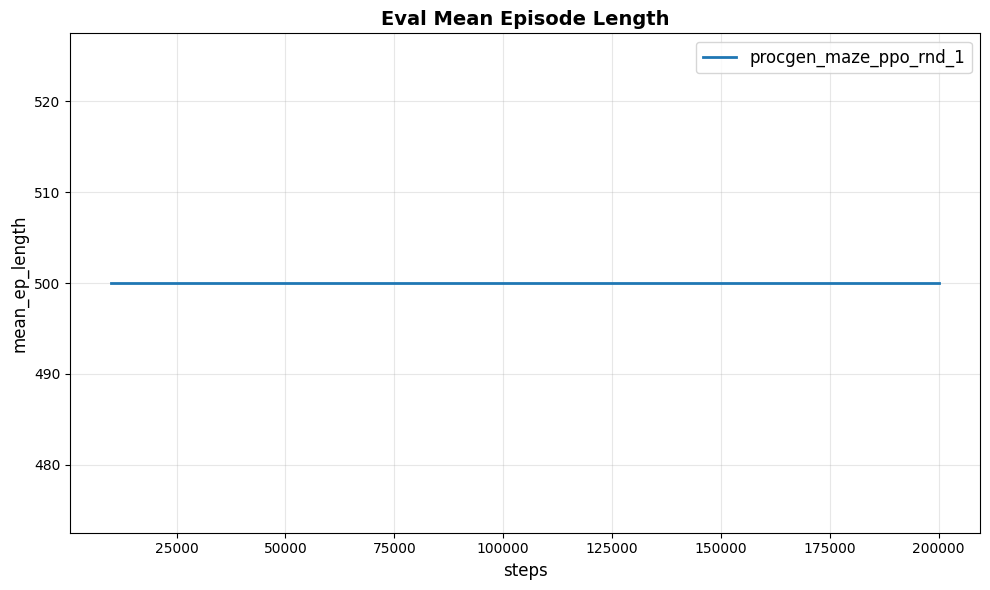

Plotting eval/mean_reward...


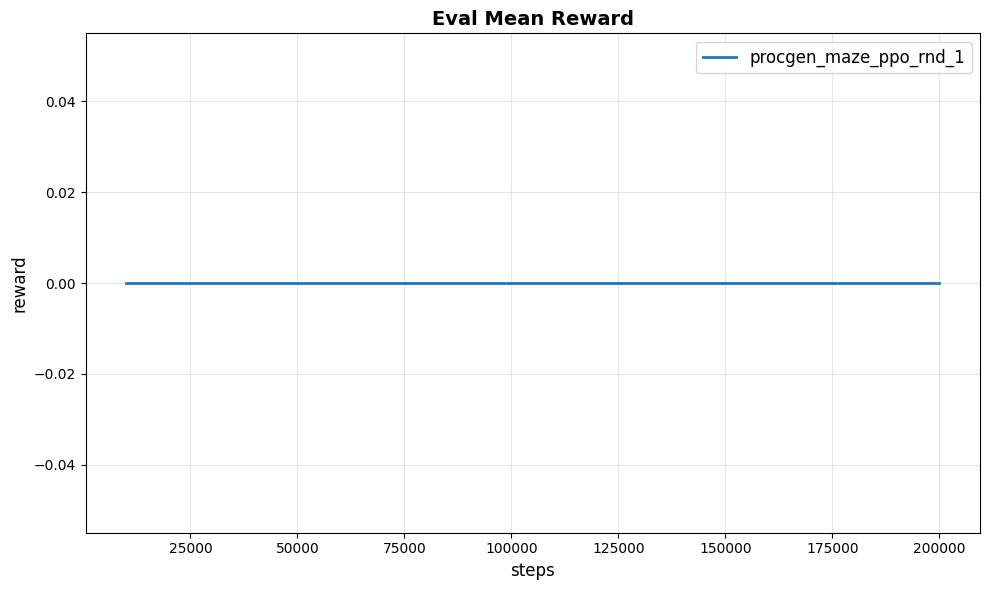


TIME

Plotting time/fps...


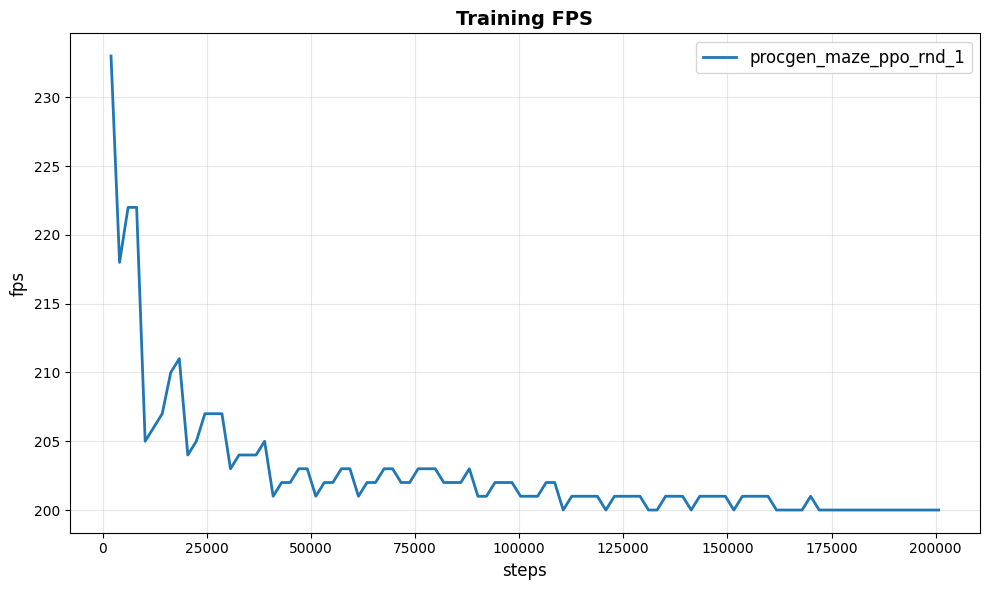


TRAIN

Plotting train/approx_kl...


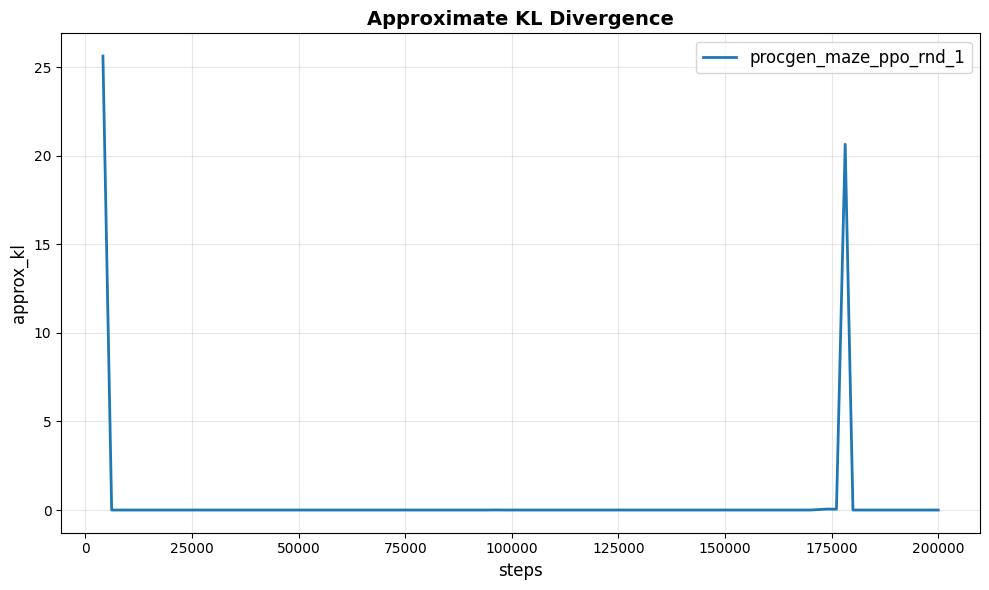

Plotting train/clip_fraction...


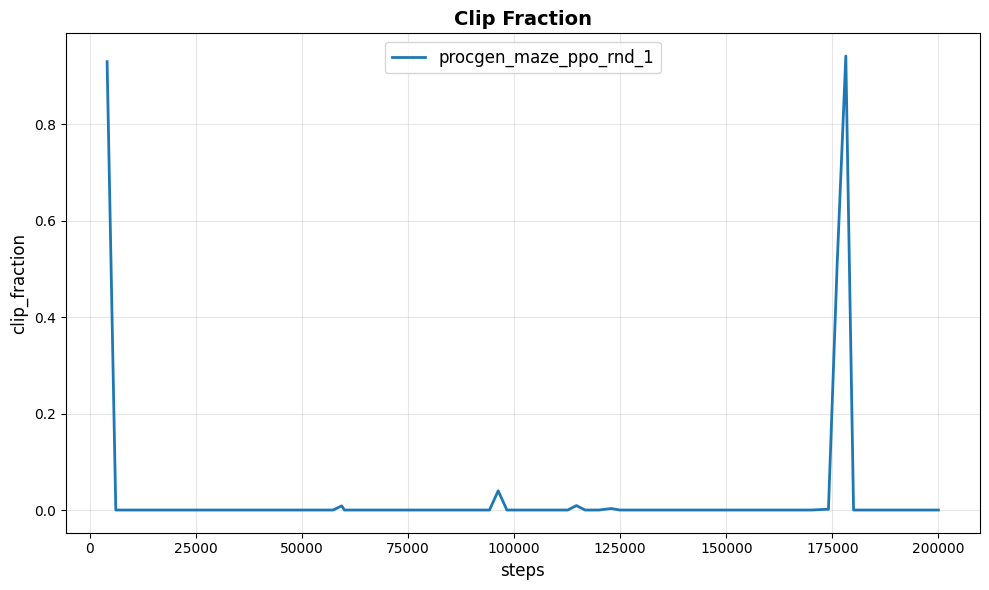

Plotting train/clip_range...


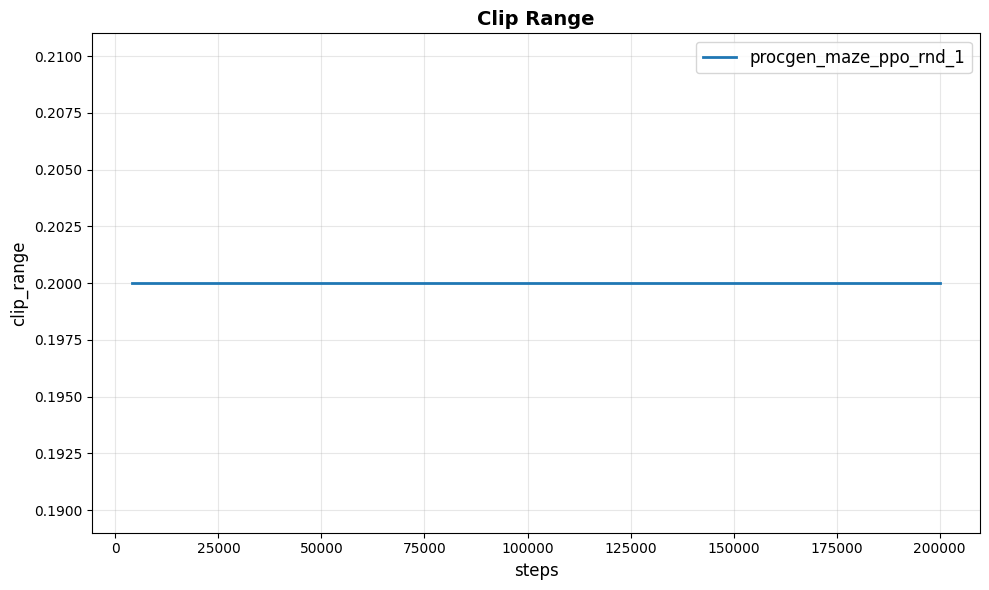

Plotting train/entropy_loss...


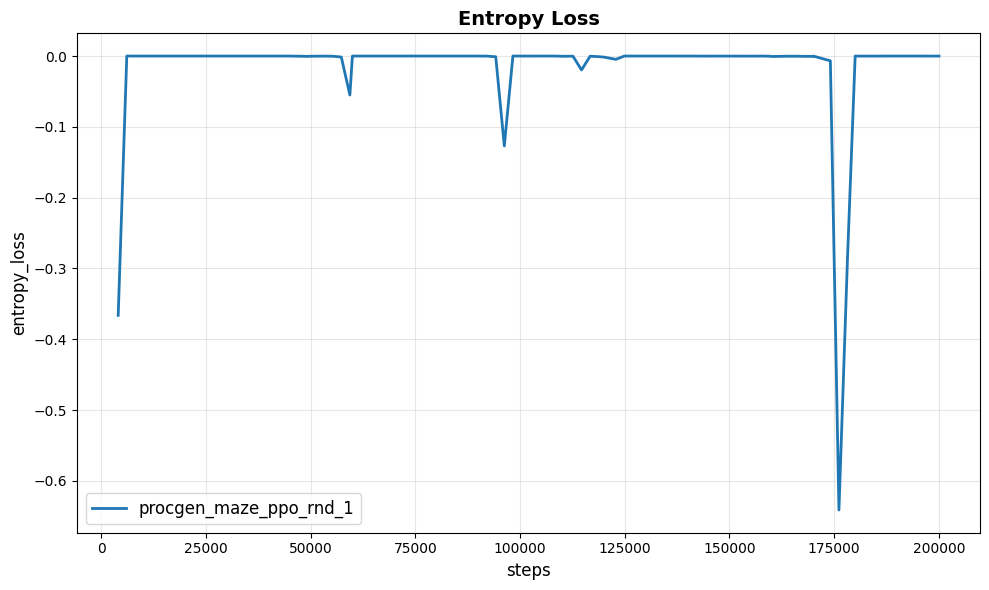

Plotting train/explained_variance...


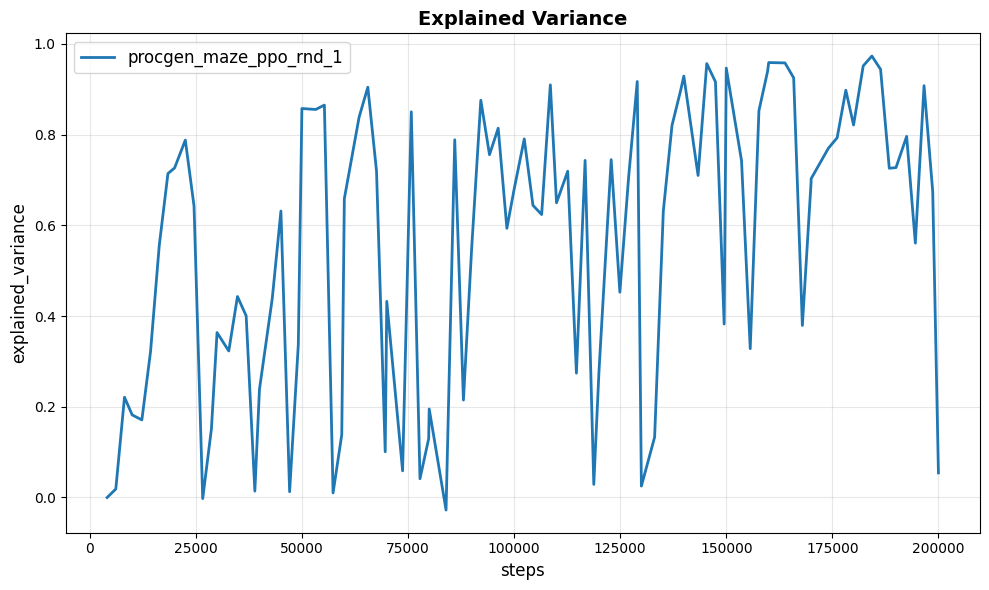

Plotting train/learning_rate...


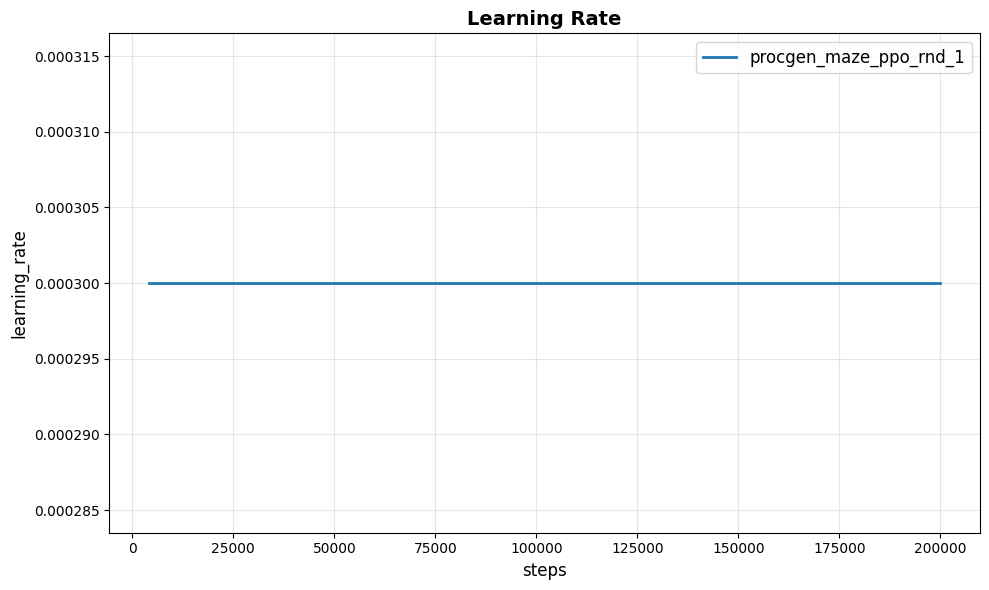

Plotting train/loss...


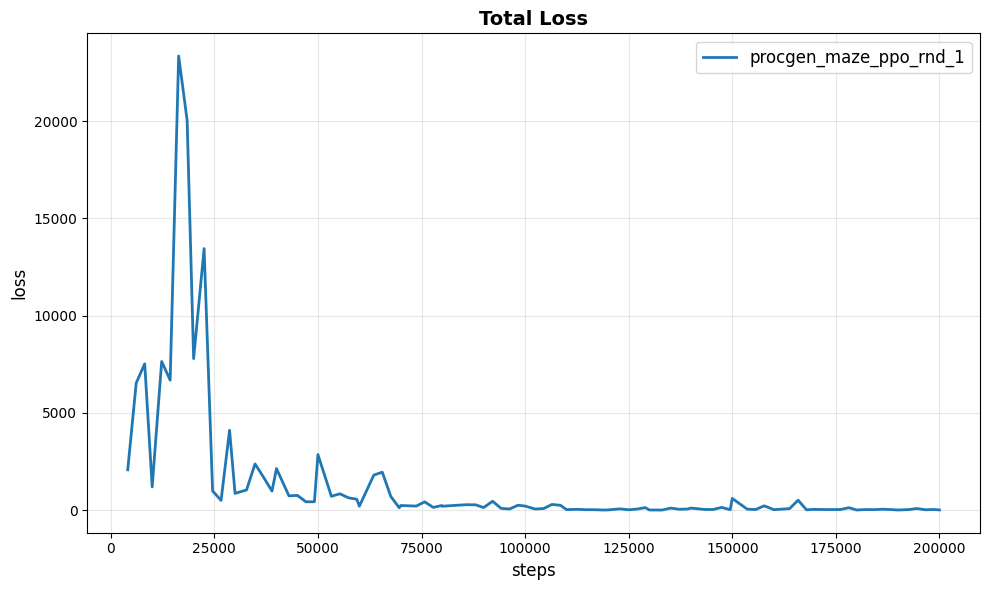

Plotting train/policy_gradient_loss...


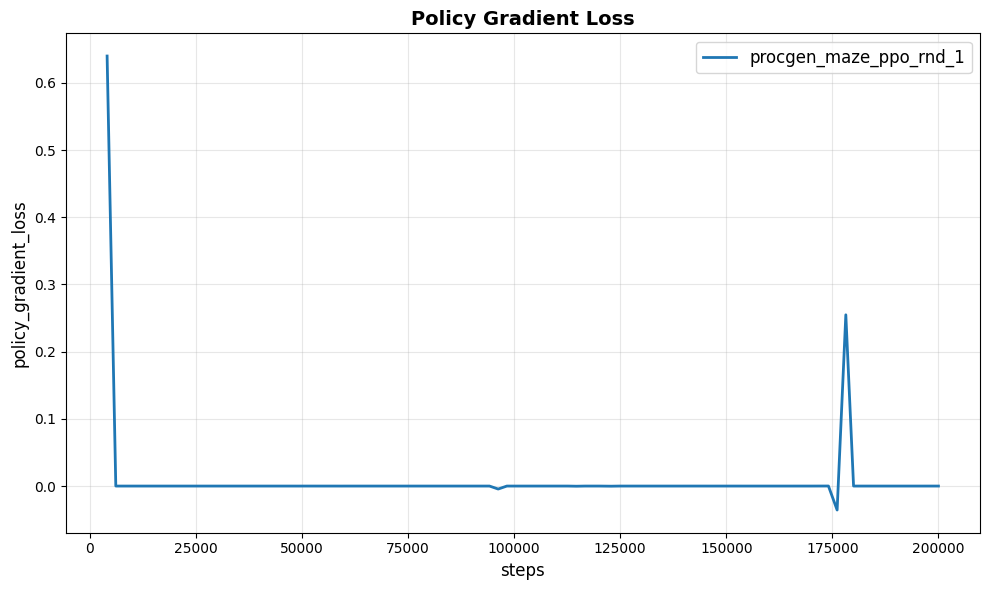

Plotting train/value_loss...


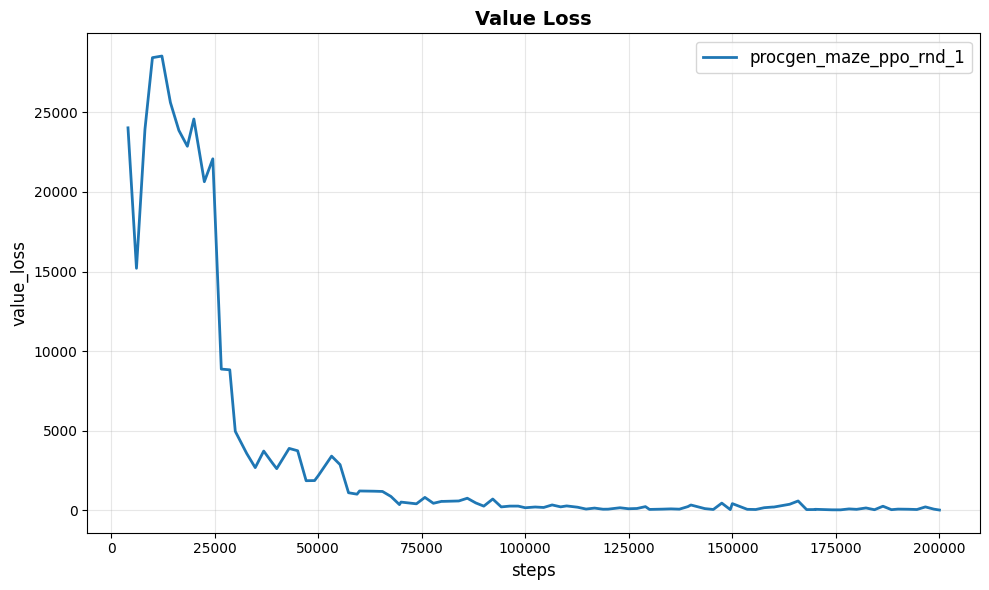

In [4]:
# ===== 定义要画的所有 tag（跟 TensorBoard 里的图一一对应） =====

groups = {
    "eval": [
        ("eval/mean_ep_length", "Eval Mean Episode Length", "mean_ep_length"),
        ("eval/mean_reward",    "Eval Mean Reward",         "reward"),
    ],
    "time": [
        ("time/fps", "Training FPS", "fps"),
    ],
    "train": [
        ("train/approx_kl",           "Approximate KL Divergence",           "approx_kl"),
        ("train/clip_fraction",       "Clip Fraction",                     "clip_fraction"),
        ("train/clip_range",          "Clip Range",                        "clip_range"),
        ("train/entropy_loss",        "Entropy Loss",                      "entropy_loss"),
        ("train/explained_variance",  "Explained Variance",                "explained_variance"),
        ("train/learning_rate",       "Learning Rate",                     "learning_rate"),
        ("train/loss",                "Total Loss",                        "loss"),
        ("train/policy_gradient_loss","Policy Gradient Loss",            "policy_gradient_loss"),
        ("train/value_loss",          "Value Loss",                        "value_loss"),
    ],
}

# ===== 一口气把所有图画出来（每个 tag 一张图） =====

for group_name, tag_list in groups.items():
    print(f"\n{'='*60}")
    print(f"{group_name.upper()}")
    print(f"{'='*60}\n")
    for tag, title, ylabel in tag_list:
        print(f"Plotting {tag}...")
        plot_tag_for_runs(
            tag=tag,
            runs_dict=RUNS,
            title=title,
            ylabel=ylabel,
        )
